# Exploratory Data Analysis: E-commerce Orders

**DecodeLabs Data Analytics Internship, Project 2**  |  Prepared by Muhammad Waqar Tahir

> **The core question:** where is this business gaining or losing value, and which patterns in the order data can we actually trust?

The input is the cleaned dataset produced in Project 1 (data cleaning; 1,200 orders, January 2023 to June 2025). This notebook follows the **Input → Process → Output** framework from the training kit.

| Stage | What happens here |
|---|---|
| **Input** | Load the cleaned orders and confirm they are what Project 1 promised |
| **Process** | Basic statistics, distributions, outliers, trends, segment comparisons, correlations, hypothesis tests |
| **Output** | Headline findings, the "so what" for the business, recommendations and limitations |

**A note on honesty.** EDA produces two kinds of result: patterns that are real, and patterns that only look real. With 1,200 rows and dozens of possible comparisons, some differences will appear by chance. Every comparison in this notebook is therefore tested, all tests are reported together, and a multiple-testing correction is applied before anything is called a finding.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import eda_utils as u     # statistics
import charts             # stakeholder-style charts

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

def show(fig):
    display(fig)
    plt.close(fig)

## 1. Input

Load the cleaned file and add a few helper columns (year, month, and a `Failed` flag for Cancelled or Returned orders).

In [2]:
df = u.load_orders(ROOT / "data" / "orders_cleaned.csv")
print(f"{len(df):,} orders x {df.shape[1]} columns")
print(f"Order dates: {df['Date'].min().date()} to {df['Date'].max().date()}  ({df['YearMonth'].nunique()} months)")
print(f"Missing values: {int(df.isna().sum().sum())}   Duplicate OrderIDs: {int(df['OrderID'].duplicated().sum())}")
df.head()

1,200 orders x 18 columns
Order dates: 2023-01-01 to 2025-06-30  (30 months)
Missing values: 0   Duplicate OrderIDs: 0


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,Year,Month,YearMonth,Failed
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10,2023,1,2023-01,False
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70,2024,8,2024-08,False
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40,2024,2,2024-02,True
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19,2023,10,2023-10,True
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04,2025,5,2025-05,False


The Project 1 guarantees hold (no missing values, no duplicate IDs), so the analysis can start from a trustworthy base. Two things to keep in mind:

- **No currency is stated** in the source, so amounts are shown as plain numbers.
- **2025 only runs to June.** Any year-on-year comparison must use January to June for every year, otherwise 2025 looks artificially small.

## 2. Process

### 2.1 Basic statistics: count, mean, median

The three statistics the guide asks for, plus spread and skew.

In [3]:
u.describe_numeric(df)

,count,mean,median,std,min,max,skew
Quantity,1200,2.95,3.00,1.41,1.00,5.00,0.03
UnitPrice,1200,356.41,364.21,197.18,11.39,699.93,-0.03
ItemsInCart,1200,5.48,5.00,2.28,1.00,10.00,0.00
TotalPrice,1200,1053.97,823.62,819.86,11.39,3456.40,0.89


In [4]:
categorical = ["Product", "OrderStatus", "PaymentMethod", "ReferralSource", "CouponCode"]
pd.DataFrame({c: df[c].value_counts().to_dict() for c in categorical}).T.fillna(0).astype(int)

,Printer,Tablet,Chair,Laptop,Desk,Monitor,Phone,Cancelled,Returned,Pending,...,Gift Card,Instagram,Email,Google,Facebook,Referral,FREESHIP,No Coupon,WINTER15,SAVE10
Product,181,179,178,173,170,163,156,0,0,0,...,0,0,0,0,0,0,0,0,0,0
OrderStatus,0,0,0,0,0,0,0,250,247,237,...,0,0,0,0,0,0,0,0,0,0
PaymentMethod,0,0,0,0,0,0,0,0,0,0,...,230,0,0,0,0,0,0,0,0,0
ReferralSource,0,0,0,0,0,0,0,0,0,0,...,0,259,250,241,228,222,0,0,0,0
CouponCode,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,313,309,292,286


**Reading the table.**

- `Quantity` (1 to 5), `UnitPrice` (about 11 to 700) and `ItemsInCart` (1 to 10) have mean and median almost equal and skew near zero: they are symmetric, and each category is spread almost evenly across the orders.
- `TotalPrice` is different. Its mean (1,054) sits well above its median (824) and its skew is 0.89. **Order value is not symmetric**, which is worth a closer look.

### 2.2 The shape of order value: mean versus median

The kit's rule: *median for skewed data, mean only for symmetric data.*

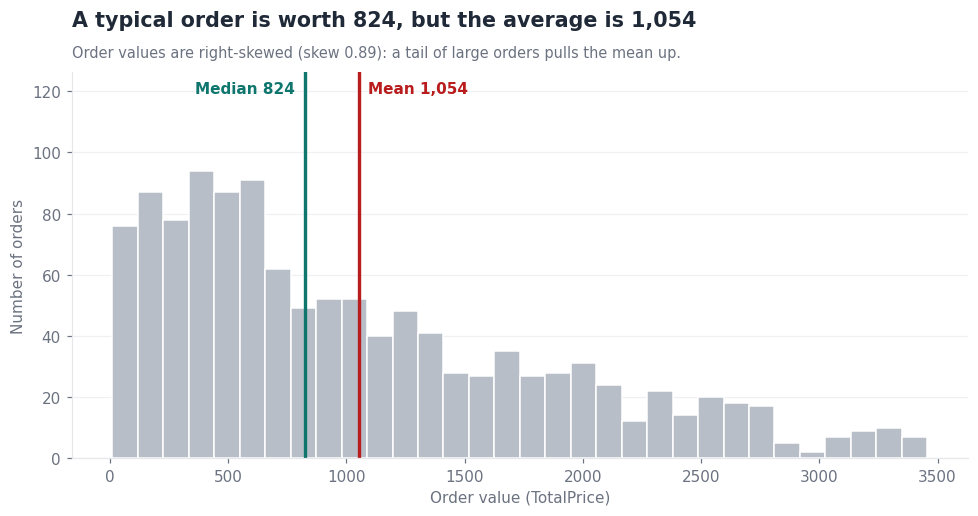

In [5]:
show(charts.fig_order_value_distribution(df))

In [6]:
five = pd.Series(u.five_number_summary(df["TotalPrice"]), name="TotalPrice").round(2)
print(five.to_string(), "\n")
print(f"Top 10% of orders hold {u.value_share_of_top(df, 0.10):.1%} of all order value")
print(f"Top 20% of orders hold {u.value_share_of_top(df, 0.20):.1%} of all order value")

min         11.39
q1         410.52
median     823.62
q3        1578.48
max       3456.40 

Top 10% of orders hold 26.3% of all order value
Top 20% of orders hold 45.5% of all order value


**Finding.** A typical order is worth about **824** (the median), but the average is **1,054**, pulled up by a tail of large orders. Quoting the mean would overstate what a typical customer spends by about 28%. The largest 20% of orders carry **45.5%** of all order value.

### 2.3 Outliers: IQR versus Z-score

Two standard tools, applied to every numeric column. The guide notes that IQR is robust to extreme values and Z-score is sensitive to them.

In [7]:
u.outlier_comparison(df)

,column,iqr_lower,iqr_upper,iqr_flagged,zscore_flagged,max_abs_z
0,Quantity,-1.00,7.00,0,0,1.46
1,UnitPrice,-317.20,1024.83,0,0,1.75
2,ItemsInCart,-0.50,11.50,0,0,1.98
3,TotalPrice,-1341.41,3330.41,8,0,2.93


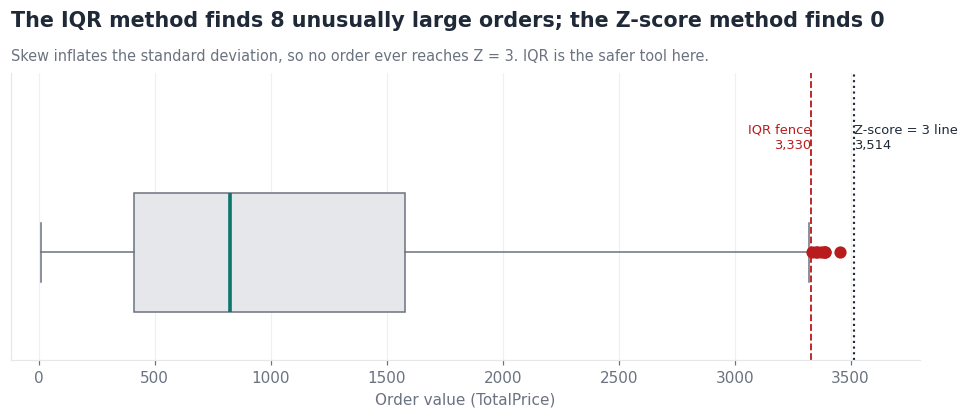

In [8]:
show(charts.fig_outliers(df))

Only `TotalPrice` has any flagged values, and the two methods disagree completely: **IQR flags 8 orders, Z-score flags none.** The reason is that skew inflates the standard deviation, so even the largest order sits at Z = 2.93, just under the cut-off of 3. On data shaped like this, Z-score would have hidden every one of them.

The next step is to decide whether the 8 are **noise** (data errors to remove) or **signal** (real events to investigate).

In [9]:
outliers = df[u.iqr_outliers(df["TotalPrice"])].sort_values("TotalPrice", ascending=False)
display(outliers[["OrderID", "Date", "Product", "Quantity", "UnitPrice", "TotalPrice", "OrderStatus"]]
        .assign(Date=lambda d: d["Date"].dt.date).reset_index(drop=True))
print("Quantity of every flagged order:", outliers["Quantity"].unique().tolist())
print("Lowest UnitPrice among them:   ", outliers["UnitPrice"].min())
print("Share of total order value:    ", f"{outliers['TotalPrice'].sum() / df['TotalPrice'].sum():.1%}")
print("Order years:                   ", outliers["Year"].value_counts().sort_index().to_dict())

,OrderID,Date,Product,Quantity,UnitPrice,TotalPrice,OrderStatus
0,ORD200789,2023-08-17,Tablet,5,691.28,3456.40,Delivered
1,ORD201122,2023-06-07,Monitor,5,678.19,3390.95,Returned
2,ORD200632,2023-05-02,Laptop,5,678.16,3390.80,Delivered
3,ORD200469,2023-11-26,Chair,5,676.98,3384.90,Cancelled
4,ORD200328,2023-02-28,Tablet,5,674.04,3370.20,Cancelled
5,ORD200107,2023-03-27,Printer,5,670.75,3353.75,Shipped
6,ORD200326,2024-07-01,Laptop,5,670.48,3352.40,Returned
7,ORD201065,2023-10-30,Printer,5,666.80,3334.00,Delivered


Quantity of every flagged order: [5]
Lowest UnitPrice among them:    666.8
Share of total order value:     2.1%
Order years:                    {2023: 7, 2024: 1}


**Verdict: signal, not noise.** All 8 are orders of the maximum quantity (5) at the highest unit prices (666 or more). The arithmetic is correct and nothing about them is impossible, so they should **not** be removed. They are simply large orders, and together they account for only 2.1% of order value. Seven fall in 2023 and one in 2024; with only 8 cases that is worth noting but not worth building a conclusion on.

### 2.4 Trends over time

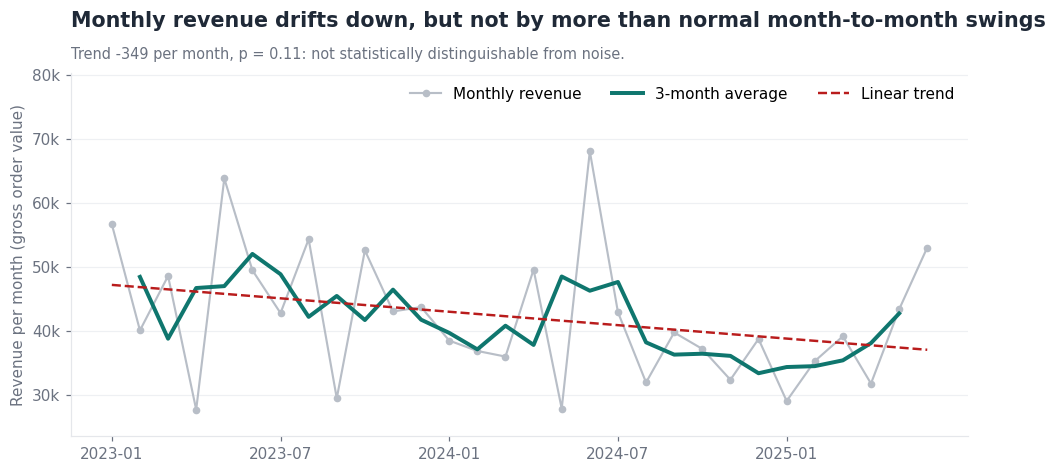

In [10]:
show(charts.fig_monthly_revenue(df))

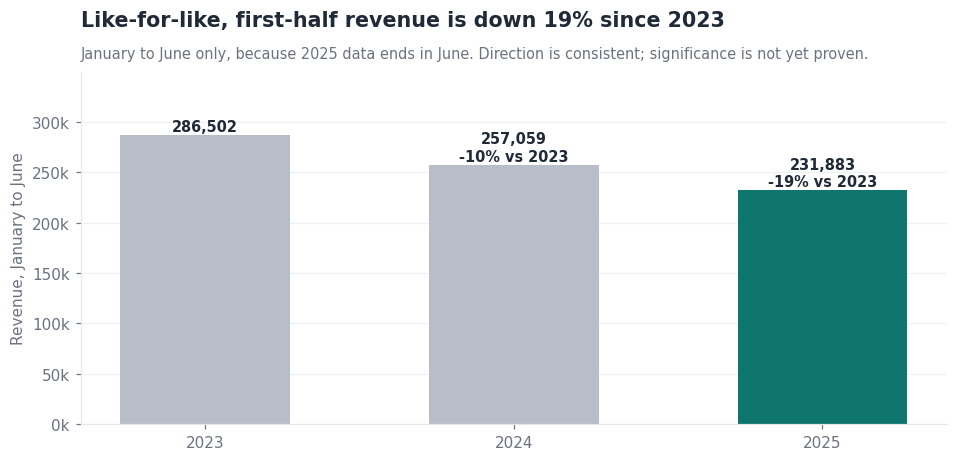

In [11]:
show(charts.fig_h1_comparison(df))

In [12]:
h1 = u.first_half_comparison(df).round(0)
h1["revenue_change_vs_2023"] = (h1["revenue"] / h1["revenue"].iloc[0] - 1).map("{:+.1%}".format)
h1

,orders,revenue,avg_order_value,median_order_value,revenue_change_vs_2023
Year,,,,,
2023,252,286502.0,1137.0,986.0,+0.0%
2024,237,257059.0,1085.0,822.0,-10.3%
2025,231,231883.0,1004.0,853.0,-19.1%


**Reading the trend.** Each January-to-June period is lower than the one before: revenue **286,502 → 257,059 → 231,883** (down 19% over two years), and average order value **1,137 → 1,085 → 1,004**. The direction is consistent.

The caution is that the month-to-month swings are large. Monthly orders average 40 with a standard deviation of 7.7, so a "bad month" of 28 orders is ordinary variation. The linear trend across all 30 months is **not statistically significant** (p = 0.11 for revenue, p = 0.34 for order counts). The fair summary is: *revenue is drifting down, the evidence is suggestive but not conclusive, and it should be monitored.*

### 2.5 Order status: where the value actually sits

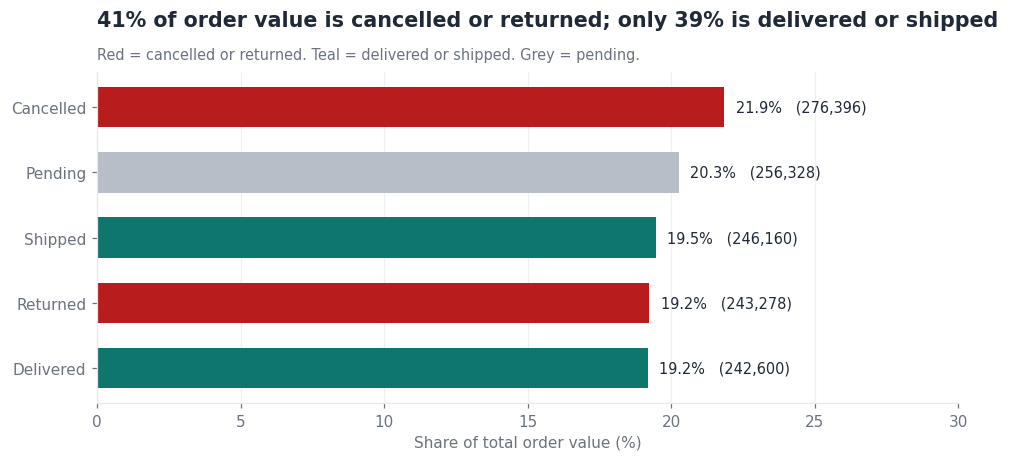

In [13]:
show(charts.fig_value_by_status(df))

In [14]:
status = u.value_by_status(df)
status.assign(value=status["value"].round(0),
              value_share=(status["value_share"] * 100).round(1),
              order_share=(status["order_share"] * 100).round(1))

,orders,value,value_share,order_share
OrderStatus,,,,
Cancelled,250,276396.0,21.9,20.8
Pending,237,256328.0,20.3,19.8
Shipped,235,246160.0,19.5,19.6
Returned,247,243278.0,19.2,20.6
Delivered,231,242600.0,19.2,19.2


**Finding.** Of about 1.26 million in gross order value, only **38.6%** has been delivered or shipped. **41.1%** (519,674) sits in cancelled or returned orders, and 20.3% is pending. Roughly two orders in five do not complete. Any revenue figure that adds up all rows overstates what has actually been fulfilled.

### 2.6 The "Pending" puzzle

An order that is genuinely pending should be recent. Age is measured against the **latest order date in the data (2025-06-30)** rather than today's date, so the result does not change depending on when the notebook is run.

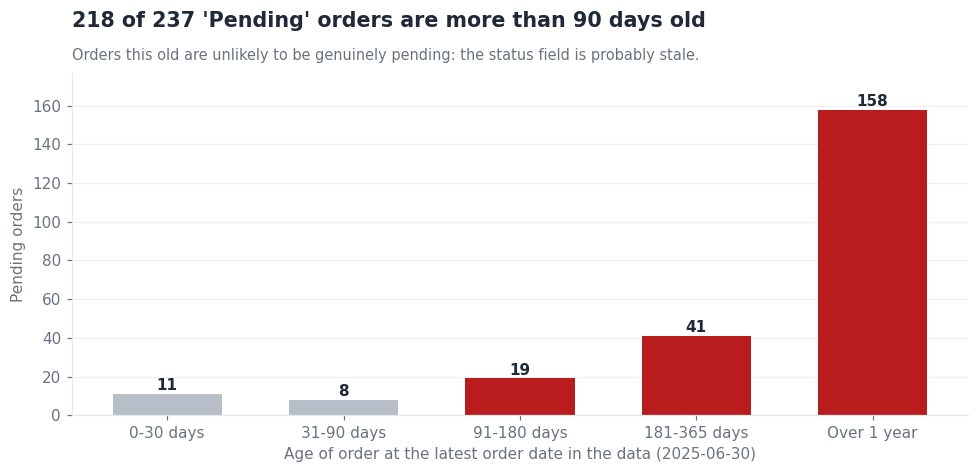

In [15]:
show(charts.fig_pending_age(df))

In [16]:
pend = u.pending_age(df)
old = pend["AgeDays"] > 90
print(f"Pending orders:                 {len(pend)}")
print(f"Older than 90 days:             {int(old.sum())}  ({old.mean():.1%})")
print(f"Older than 1 year:              {int((pend['AgeDays'] > 365).sum())}")
print(f"Value of those over 90 days:    {pend.loc[old, 'TotalPrice'].sum():,.0f}")

Pending orders:                 237
Older than 90 days:             218  (92.0%)
Older than 1 year:              158
Value of those over 90 days:    235,082


**Finding.** **218 of 237 pending orders (92%) are more than 90 days old**, and 158 are more than a year old. Orders do not stay genuinely pending for a year, so the most likely explanations are a status field that is not being updated, or orders that were abandoned and never closed. Either way, about **235,000 of order value is sitting in a status nobody can trust.** This is the single most actionable finding in the data, because it is a process problem the business can check and fix.

### 2.7 Segments: does anything explain the failures?

If 41% of orders fail, the natural next question is whether some product, payment method, channel or coupon is responsible. Each is compared against the overall rate.

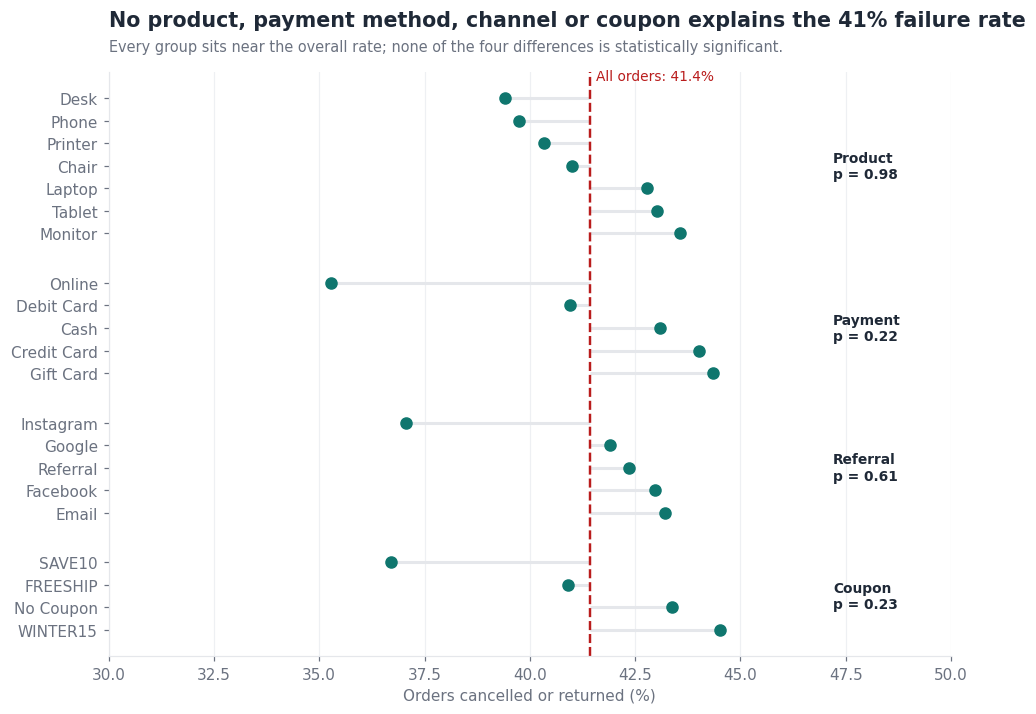

In [17]:
show(charts.fig_failure_by_segment(df))

In [18]:
coupon = df.groupby("CouponCode").agg(orders=("OrderID", "count"),
                                      median_order_value=("TotalPrice", "median"),
                                      failure_rate=("Failed", "mean"))
coupon["failure_rate"] = (coupon["failure_rate"] * 100).round(1)
coupon

,orders,median_order_value,failure_rate
CouponCode,,,
FREESHIP,313,793.400,40.9
No Coupon,309,834.120,43.4
SAVE10,286,823.065,36.7
WINTER15,292,838.710,44.5


**Finding: a null result, and an important one.** Failure rates range from about 35% to 45% across groups, and some (Online payment at 35.3%, SAVE10 at 36.7%) look lower at a glance. But with roughly 155 to 315 orders per group, gaps of this size are what random variation produces. None of the four comparisons is significant (p = 0.22 to 0.98). **Nothing in this file explains why orders fail**, which itself tells the business the answer needs data it does not yet collect (cancellation and return reasons).

The same applies to coupons: 74% of orders use one, yet median order value is almost identical with and without a coupon (about 793 to 839) and the failure rate does not differ significantly.

### 2.8 Correlation

Pearson's *r* measures the strength and direction of a *linear* relationship.

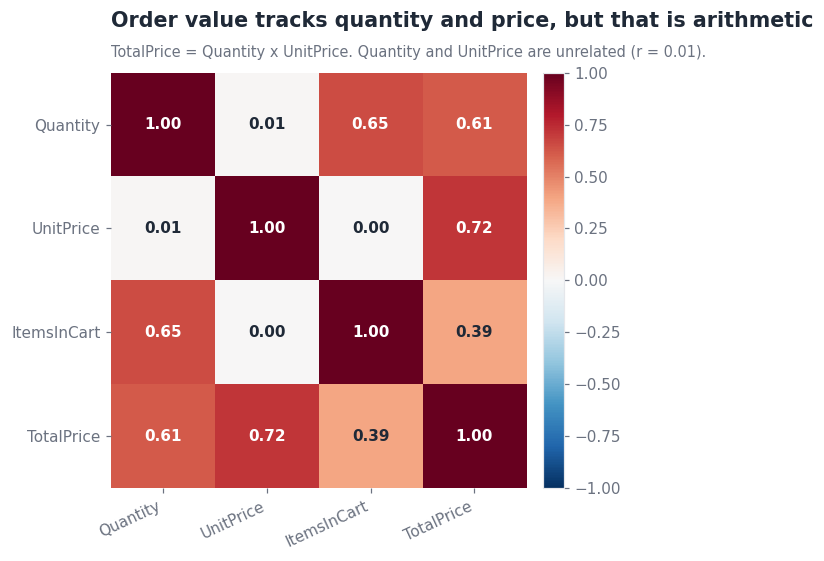

In [19]:
show(charts.fig_correlation(df))

In [20]:
print("Spearman (rank) correlation, for robustness to skew:")
u.correlation_matrix(df, method="spearman")

Spearman (rank) correlation, for robustness to skew:


,Quantity,UnitPrice,ItemsInCart,TotalPrice
Quantity,1.000,0.015,0.636,0.599
UnitPrice,0.015,1.000,0.004,0.755
ItemsInCart,0.636,0.004,1.000,0.365
TotalPrice,0.599,0.755,0.365,1.000


**Reading the heatmap, with the golden rule: correlation is a clue, not a verdict.**

- `TotalPrice` correlates with `Quantity` (0.61) and `UnitPrice` (0.72), but that is **arithmetic, not insight**: `TotalPrice` is defined as Quantity × UnitPrice. It would be a mistake to report it as a finding.
- `Quantity` and `UnitPrice` are unrelated (r = 0.01): customers do not buy more of cheaper items, or fewer of expensive ones.
- `ItemsInCart` correlates with `Quantity` (0.65) because quantity can never exceed the cart size (true in all 1,200 orders). Again structural, not behavioural.

There is no relationship here that reveals customer behaviour. The rank-based (Spearman) version tells the same story.

### 2.9 Formal testing, with a multiple-testing correction

Looking at many charts means running many implicit tests. If 14 comparisons are made at the usual 5% threshold, the chance that at least one looks "significant" by luck alone is about 51%. So all 14 tests are listed together and adjusted using the **Holm-Bonferroni** method, which controls the chance of *any* false positive.

In [21]:
tests = u.run_hypothesis_tests(df)
view = tests[["question", "method", "p_raw", "p_holm", "significant_raw", "significant_after_correction"]].copy()
view[["p_raw", "p_holm"]] = view[["p_raw", "p_holm"]].round(3)
view

,question,method,p_raw,p_holm,significant_raw,significant_after_correction
0,Are monthly order counts trending up or down?,Linear regression on month,0.343,1.000,False,False
1,Is monthly revenue trending up or down?,Linear regression on month,0.111,1.000,False,False
2,Is order value changing over time?,Spearman correlation,0.211,1.000,False,False
3,Do some calendar months get more orders?,Chi-square (exposure-adjusted),0.336,1.000,False,False
4,Does order value differ by product?,Kruskal-Wallis,0.820,1.000,False,False
5,Does order value differ by payment method?,Kruskal-Wallis,0.450,1.000,False,False
6,Does order value differ by referral source?,Kruskal-Wallis,0.891,1.000,False,False
7,Does order value differ by coupon?,Kruskal-Wallis,0.910,1.000,False,False
8,Does order value differ by order status?,Kruskal-Wallis,0.627,1.000,False,False
9,Does the cancel/return rate differ by product?,Chi-square,0.977,1.000,False,False


In [22]:
print(f"Tests run: {len(tests)}")
print(f"'Significant' before correction: {int(tests['significant_raw'].sum())}")
print(f"Significant after correction:    {int(tests['significant_after_correction'].sum())}")
print(f"\nChance of at least one false positive in 14 tests at 5%: {1 - 0.95**14:.0%}")

Tests run: 14
'Significant' before correction: 1
Significant after correction:    0

Chance of at least one false positive in 14 tests at 5%: 51%


**Only one test looks significant before correction**: whether the full status mix (Delivered, Shipped, Pending, Cancelled, Returned) differs by referral source (p = 0.005). After correction its adjusted p-value is **0.073**, above the 0.05 line. That is exactly what one lucky result among 14 tests looks like.

It is reasonable to keep as a **hypothesis worth re-testing on new data**, and unreasonable to report as a finding. Every other test, including all trends and every product, payment, channel and coupon comparison, is comfortably non-significant.

## 3. Output

### 3.1 The "So what?" test

Statistics only matter once they are translated into what they mean for the business.

| What the data says | What it means for the business |
|---|---|
| Median order is 824, mean is 1,054; top 20% of orders carry 45.5% of value | Reports and targets should use the **median** for a typical customer, and the business relies heavily on a minority of larger orders |
| 41.4% of orders (41.1% of value) are cancelled or returned; only 38.6% of value is delivered or shipped | **Gross order value is about 2.6 times what has actually been delivered or shipped.** Fulfilment is the biggest lever available |
| 218 of 237 "Pending" orders are over 90 days old (about 235,000 of value) | The status data is unreliable. A **process fix** would clean up the picture and could recover or write off stuck orders |
| No product, payment method, channel or coupon explains the failure rate | The cause is **not visible in the current data**; cancellation and return reasons must be captured |
| First-half revenue down 10% then 19% versus 2023, but within normal monthly swings | A **watch item**, not yet an alarm |
| Coupons are used on 74% of orders with no measurable difference in value or failures | Discounting is **not demonstrably paying for itself**, though this file cannot show its cost |

### 3.2 Recommendations

1. **Audit the order-status process.** Investigate the 218 stale pending orders (about 235,000 in value). Confirm which are real, close or cancel the rest, and add an automatic alert for orders pending beyond a set limit such as 30 days.
2. **Start recording why orders fail.** Add cancellation and return reason codes and status-change timestamps. The current data cannot explain a 41% failure rate, and that rate is the largest opportunity in the file.
3. **Report the median alongside the mean**, and use the IQR method (not Z-score) to flag unusual orders.
4. **Track monthly revenue on a control chart** and revisit after the second half of 2025. Act if the decline keeps going beyond normal variation.
5. **Test coupons properly** before further discounting: run a controlled comparison, and add the discount amount to the data (currently `TotalPrice` ignores it).
6. **Follow up the 8 largest orders** as a group of high-value accounts. Half of them were cancelled or returned, so it is worth understanding why.

### 3.3 Limitations

- **The data looks synthetic or simplified.** Categories are almost perfectly evenly distributed and every `ShippingAddress` is a house number on "Main St", so location cannot be analysed. Real customer data usually shows more structure than this.
- **`TotalPrice` ignores coupons and shipping**, so discounts and margins cannot be measured.
- **`UnitPrice` varies widely within one product** (a laptop ranges from about 18 to 700), so it is not a stable catalogue price.
- **Observational data.** Nothing here proves cause and effect.
- **2025 covers only six months**, which limits time-based conclusions.
- **Currency and cost data are absent**, so profit cannot be assessed.

### 3.4 Consistency check

Confirms that the numbers written in the text above match what the code actually calculates, so the narrative cannot drift out of sync with the data.

In [23]:
m = u.headline_metrics(df)

assert round(m["mean_order_value"]) == 1054 and round(m["median_order_value"]) == 824
assert abs(m["top20_value_share"] - 0.455) < 0.001
assert m["iqr_outlier_count"] == 8 and m["zscore_outlier_count"] == 0 and round(m["max_z"], 2) == 2.93
assert m["outlier_all_qty5"] and m["outlier_failed"] == 4 and abs(m["outlier_value_share"] - 0.021) < 0.001
assert m["failed_orders"] == 497 and abs(m["failed_value_share"] - 0.411) < 0.001
assert abs(m["fulfilled_value_share"] - 0.386) < 0.001
assert m["pending_orders"] == 237 and m["pending_over_90"] == 218 and m["pending_over_365"] == 158
assert round(m["pending_over_90_value"], -3) == 235000
assert [round(r["revenue"]) for r in m["h1"]] == [286502, 257059, 231883]
assert m["n_tests"] == 14 and m["n_significant_raw"] == 1 and m["n_significant_corrected"] == 0
assert abs(m["coupon_use_share"] - 0.7425) < 0.001

print("All figures quoted in the text match the calculations.")

All figures quoted in the text match the calculations.


## Conclusion

- **The strongest, most actionable finding is a process problem:** 92% of "pending" orders are stale, and 41% of order value is cancelled or returned, so reported revenue is well above real revenue.
- **The statistical picture is mostly flat**, and this notebook says so. After correcting for the 14 tests run, no trend or segment difference is distinguishable from chance.
- **Outliers were investigated, not deleted.** The 8 large orders are legitimate, and the IQR method found what Z-score could not.
- **The data cannot yet explain why orders fail**, and identifying the missing fields is itself a useful result.